# Block 0 – Imports & Configuration

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

plt.style.use("seaborn-v0_8")


# Block 1 – Objective

The objective of this notebook is to **detect sales anomalies** using
unsupervised time series analysis techniques.

Specifically, we aim to:
- Identify **anomalous sales spikes**
- Detect **unusual drops**
- Analyze whether the anomalies are associated with specific items, stores, or time periods

This type of analysis is particularly useful in the context of:
- Retail monitoring
- Early detection of stock issues
- Evaluation of promotional events or operational failures

# Block 2 – Load Prepared Dataset

In [3]:
# Load processed data in notebook 03_eda_visualization.ipynb
df = pd.read_pickle("../data/processed/demand_forecasting_features.pkl") 

df.head()


,date,store,item,sales,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_std_7,rolling_mean_14,rolling_std_14,rolling_mean_28,rolling_std_28,day_of_week,week_of_year,month,year
0,2013-01-29,6,1,6,9.0,3.0,11.0,20.0,7.428571,2.572751,8.214286,2.860300,9.428571,3.414876,1,5,1,2013
1,2013-01-29,8,12,57,48.0,38.0,41.0,54.0,47.571429,7.184640,47.214286,7.747740,48.250000,8.149642,1,5,1,2013
2,2013-01-29,8,49,19,12.0,22.0,10.0,12.0,18.285714,4.151879,17.571429,4.685728,18.500000,5.357584,1,5,1,2013
3,2013-01-29,3,10,47,29.0,42.0,36.0,38.0,46.142857,10.510765,45.214286,9.099269,45.000000,8.485281,1,5,1,2013
4,2013-01-29,10,29,42,40.0,46.0,38.0,35.0,48.714286,5.822780,46.857143,9.670392,44.785714,9.496031,1,5,1,2013


In [5]:
df.shape
df.isna().sum().sort_values(ascending=False)


date               0
store              0
item               0
sales              0
lag_1              0
lag_7              0
lag_14             0
lag_28             0
rolling_mean_7     0
rolling_std_7      0
rolling_mean_14    0
rolling_std_14     0
rolling_mean_28    0
rolling_std_28     0
day_of_week        0
week_of_year       0
month              0
year               0
dtype: int64

# Block 3 – Aggregation for Anomaly Detection

Before detecting anomalies, we aggregate the series.
This reduces noise and makes the analysis interpretable.

## 3.1 Total daily sales

In [6]:
daily_sales = (
    df.groupby("date")["sales"]
    .sum()
    .reset_index()
    .sort_values("date")
)

daily_sales.head()


,date,sales
0,2013-01-29,13724
1,2013-01-30,13391
2,2013-01-31,14724
3,2013-02-01,17473
4,2013-02-02,18323


## 3.2 Initial Visualization

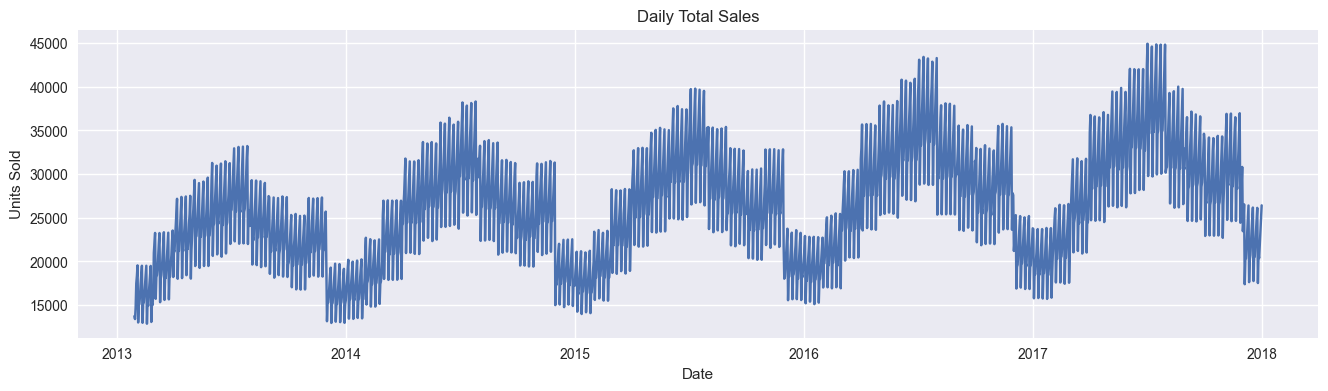

In [9]:
plt.figure(figsize=(16,4))
plt.plot(daily_sales["date"], daily_sales["sales"])
plt.title("Daily Total Sales")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.show()


# Block 4 – Statistical Baseline (Rolling Z-Score)

First we use a **simple statistical** approach as a baseline.

## 4.1 Rolling mean & std

In [10]:
window = 30

daily_sales["rolling_mean"] = daily_sales["sales"].rolling(window).mean()
daily_sales["rolling_std"] = daily_sales["sales"].rolling(window).std()

daily_sales["z_score"] = (
    (daily_sales["sales"] - daily_sales["rolling_mean"]) /
    daily_sales["rolling_std"]
)


## 4.2 Anomalies Detection

In [15]:
z_threshold = 2

daily_sales["anomaly_z"] = daily_sales["z_score"].abs() > z_threshold


## 4.3 Visualization

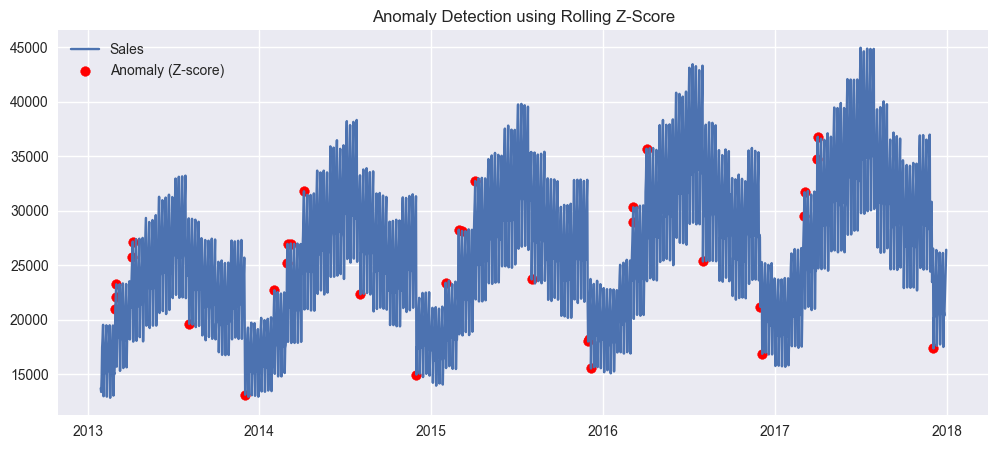

In [16]:
plt.figure(figsize=(12,5))
plt.plot(daily_sales["date"], daily_sales["sales"], label="Sales")

plt.scatter(
    daily_sales.loc[daily_sales["anomaly_z"], "date"],
    daily_sales.loc[daily_sales["anomaly_z"], "sales"],
    color="red",
    label="Anomaly (Z-score)",
)

plt.title("Anomaly Detection using Rolling Z-Score")
plt.legend()
plt.show()


## 4.4 Zooming in a particlular year

In [17]:
year_to_plot = 2016

subset = daily_sales[
    daily_sales["date"].dt.year == year_to_plot
]


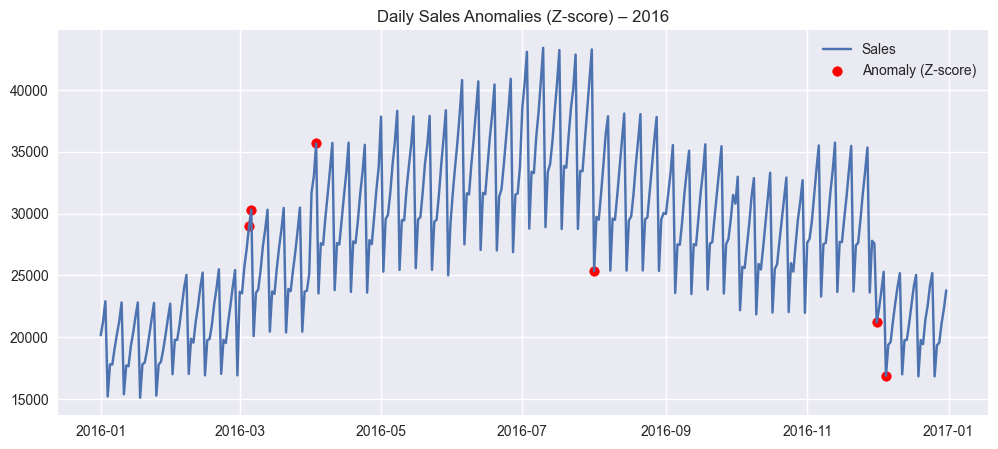

In [18]:
plt.figure(figsize=(12,5))
plt.plot(subset["date"], subset["sales"], label="Sales")

plt.scatter(
    subset.loc[subset["anomaly_z"], "date"],
    subset.loc[subset["anomaly_z"], "sales"],
    color="red",
    label="Anomaly (Z-score)",
)

plt.title(f"Daily Sales Anomalies (Z-score) – {year_to_plot}")
plt.legend()
plt.show()

# Block 5 – Model-Based Anomaly Detection (Isolation Forest)

Now we move to an **unsupervised ML-based** approach.

## 5.1 Feature preparation

In [19]:
X = daily_sales[["sales"]].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


## 5.2 Train Isolation Forest

In [20]:
iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42
)

daily_sales["anomaly_if"] = iso_forest.fit_predict(X_scaled)
daily_sales["anomaly_if"] = daily_sales["anomaly_if"] == -1


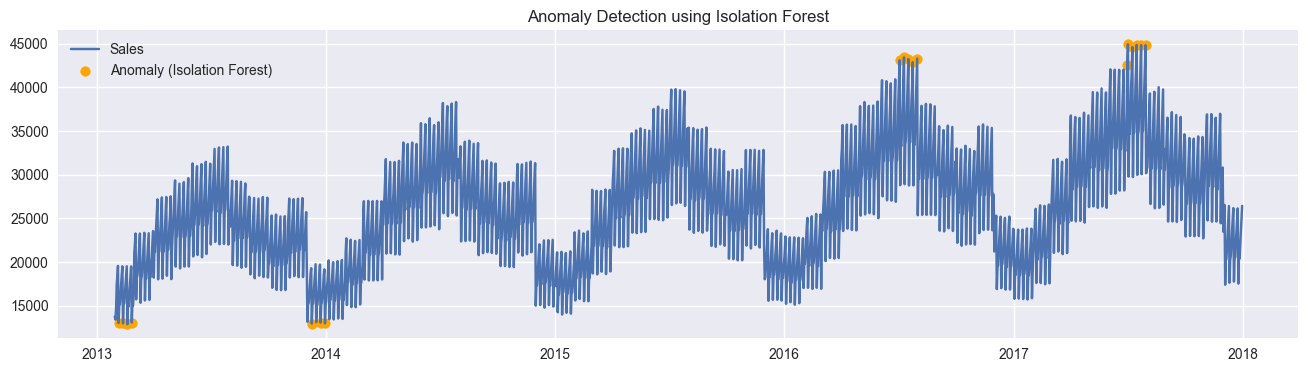

In [22]:
plt.figure(figsize=(16,4))
plt.plot(daily_sales["date"], daily_sales["sales"], label="Sales")

plt.scatter(
    daily_sales.loc[daily_sales["anomaly_if"], "date"],
    daily_sales.loc[daily_sales["anomaly_if"], "sales"],
    color="orange",
    label="Anomaly (Isolation Forest)",
)

plt.title("Anomaly Detection using Isolation Forest")
plt.legend()
plt.show()


# Block 6 — Interpretation of detected anomalies

in this block, we analyze the results obtained from the anomaly detection models
applied to the sales time series.

## 6.1 Anomalies detected using Z-score

The Z-score–based method identifies anomalies as observations whose deviation
from the mean exceeds a predefined threshold (`z_threshold`).

This approach implicitly assumes a relatively stable data distribution over time,
which causes it to mainly flag extreme peaks or drops in the series.

Given the strong seasonality and high daily variability of sales, this method may
fail to detect anomalies when the threshold is too high, or generate false positives
when the threshold is too low.

## 6.2 Anomalies detected using Isolation Forest

The Isolation Forest model detects anomalies by identifying observations that can
be isolated quickly in the feature space.

In this case, the model mainly detects the most extreme values in the time series
(global maxima and minima), as it does not explicitly incorporate temporal or
seasonal information.

This behavior is consistent with the nature of the algorithm and is suitable for
detecting global anomalies, such as unusually high sales spikes or sharp drops.


# BLoack 7. Limitations of the applied approach

Although the applied models are able to identify outliers in the sales time series,
several limitations should be considered.


## 7.1 Lack of temporal context

The applied models do not explicitly incorporate the temporal structure of the
series (trend, seasonality, or calendar effects).

As a result, values that are normal during high-demand periods may be incorrectly
classified as anomalies.


## 7.2 Global vs contextual anomalies

The current approach is better suited for detecting global anomalies, meaning
values that are extreme when compared to the entire dataset.

However, it is not capable of detecting contextual anomalies, such as unexpected
drops during peak seasons or unusual spikes within a specific seasonal pattern.


# Block 8 — Conclusions and future improvements

## 8.1 Conclusions

- Simple statistical methods such as Z-score allow for quick detection of extreme
  values but are sensitive to seasonality and variability.
- Isolation Forest effectively identifies global anomalies without making strong
  distributional assumptions.
- Both approaches provide a solid first step for detecting unusual behaviors in
  sales time series data.


## 8.2 Future improvements

Potential future improvements include:

- Incorporating temporal features (day of week, month, rolling statistics) into
  the anomaly detection models.
- Performing anomaly detection on residuals after time series decomposition
  (trend + seasonality).
- Exploring time-series–specific anomaly detection models such as Prophet or
  STL-based approaches.
